<a href="https://colab.research.google.com/github/Kaustav-codes/Badge/blob/main/MinorProjectWOA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Importing Libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error
from statsmodels.nonparametric.kernel_regression import KernelReg
import warnings
warnings.filterwarnings("ignore")


**Generating Synthetic Time Series Data**

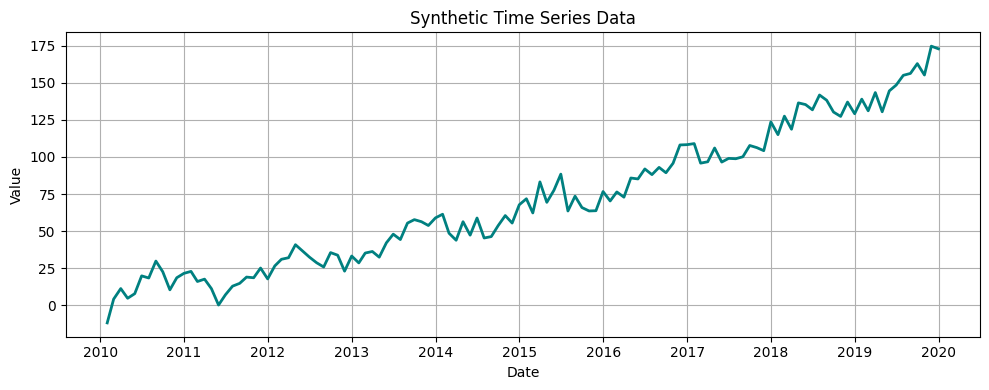

In [2]:
np.random.seed(47)
n = 120
t = np.arange(n)
dates = pd.date_range(start='2010-01-01', periods=n, freq='M')

# Generate nonlinear trend
a = np.random.uniform(0.005, 0.02)
b = np.random.uniform(-0.5, 0.5)
c = np.random.uniform(8, 12)
trend = a * (t ** 2) + b * t + c

# Seasonality
seasonality_amp = np.random.uniform(6, 14)
seasonality_freq = np.random.uniform(0.8, 1.2)
seasonality_phase = np.random.uniform(0, 2*np.pi)
seasonality = seasonality_amp * np.sin(seasonality_freq * np.linspace(0, 12 * np.pi, n) + seasonality_phase)

# Cyclic component
cycle_period = np.random.randint(50, 90)
cycle_amp = np.random.uniform(1, 7)
cycle = cycle_amp * np.sin(2*np.pi*t / cycle_period + np.random.uniform(0, 2*np.pi))

# Random noise
noise = np.random.normal(0, 5, n)

# Final signal
values = trend + seasonality + cycle + noise

# Create DataFrame
df = pd.DataFrame({'Date': dates, 'Value': values}).set_index('Date')

# Visualize
plt.figure(figsize=(10,4))
plt.plot(df.index, df['Value'], color='teal', linewidth=2)
plt.title("Synthetic Time Series Data")
plt.xlabel("Date")
plt.ylabel("Value")
plt.grid(True)
plt.tight_layout()
plt.show()


**Defining Train/Test Split & Expanding Window**

In [3]:
train_size = int(n * 0.95)
test_size = n - train_size
train = df.iloc[:train_size]
test = df.iloc[train_size:]

initial_window = int(n * 0.5)
max_window = len(train) - 1
increment = 1

bw_lower, bw_upper = 0.1, 5.0


**Define Evaluation Function (MSE)**  *[This computes MSE for a given bandwidth.]*

In [4]:
def eval_bandwidth_mse(bw, X_train, y_train, X_val, y_val):
    try:
        model = KernelReg(endog=y_train, exog=X_train, var_type='c', bw=[float(bw)])
        y_pred, _ = model.fit(X_val)
        return mean_squared_error(y_val, y_pred)
    except Exception:
        return np.inf


**Implement Whale Optimization Algorithm (WOA)**

In [5]:
# The Whale Optimization Algorithm mimics the hunting behavior of humpback whales:
# Encircling prey
# Bubble-net attack (spiral movement)
# Search for prey (exploration)

def woa_optimize_bw(X_train, y_train, X_val, y_val,
                    lb=bw_lower, ub=bw_upper,
                    pop_size=10, max_iter=20, seed=None):
    if seed is not None:
        np.random.seed(seed)

    positions = np.random.uniform(lb, ub, pop_size).astype(float)
    fitness = np.full(pop_size, np.inf)

    for i in range(pop_size):
        fitness[i] = eval_bandwidth_mse(positions[i], X_train, y_train, X_val, y_val)

    leader_idx = np.argmin(fitness)
    leader_pos = float(positions[leader_idx])
    leader_score = float(fitness[leader_idx])

    for t_iter in range(max_iter):
        a = 2 * (1 - t_iter / float(max_iter))  # linearly decreases from 2 → 0
        for i in range(pop_size):
            r1, r2, p = np.random.rand(), np.random.rand(), np.random.rand()
            A = 2 * a * r1 - a
            C = 2 * r2

            if p < 0.5:
                if abs(A) < 1:
                    new_pos = leader_pos - A * abs(C * leader_pos - positions[i])
                else:
                    rand_idx = np.random.randint(pop_size)
                    X_rand = positions[rand_idx]
                    new_pos = X_rand - A * abs(C * X_rand - positions[i])
            else:
                b = 1
                l = np.random.uniform(-1, 1)
                new_pos = abs(leader_pos - positions[i]) * np.exp(b * l) * np.cos(2*np.pi*l) + leader_pos

            new_pos = np.clip(new_pos, lb, ub)
            new_fit = eval_bandwidth_mse(new_pos, X_train, y_train, X_val, y_val)

            if new_fit < fitness[i]:
                positions[i] = new_pos
                fitness[i] = new_fit

            if new_fit < leader_score:
                leader_score = new_fit
                leader_pos = float(new_pos)

    return float(leader_pos), float(leader_score)


**Expanding Window Forecasting with WOA ** *[For each expanding window, we find the best bandwidth using WOA.]*

In [6]:
window_mse = []
print(f"{'Train Window End':<18} {'Best BW (WOA)':<15} {'MSE':<12}")
print("-" * 48)

WOA_POP, WOA_ITERS, WOA_SEED = 10, 20, 42

for end in range(initial_window, max_window, increment):
    val_end = min(end + increment, max_window)
    if val_end <= end:
        continue

    X_train = np.arange(end).reshape(-1, 1)
    y_train = train['Value'].values[:end]
    X_val = np.arange(end, val_end).reshape(-1, 1)
    y_val = train['Value'].values[end:val_end]

    best_bw, best_mse = woa_optimize_bw(X_train, y_train, X_val, y_val,
                                        lb=bw_lower, ub=bw_upper,
                                        pop_size=WOA_POP, max_iter=WOA_ITERS, seed=WOA_SEED)

    window_mse.append((val_end, best_bw, best_mse))
    print(f"{val_end:<18} {best_bw:<15.4f} {best_mse:<12.6f}")

window_results = pd.DataFrame(window_mse, columns=['WindowEnd', 'BestBW', 'MSE'])


Train Window End   Best BW (WOA)   MSE         
------------------------------------------------
61                 1.5634          0.000000    
62                 5.0000          40.663427   
63                 3.5642          167.483794  
64                 5.0000          67.337552   
65                 4.9618          0.000000    
66                 0.2136          0.155776    
67                 0.1430          376.045458  
68                 2.9769          0.000000    
69                 1.8409          6.405996    
70                 2.1509          0.000001    
71                 3.7659          0.000000    
72                 5.0000          145.657249  
73                 3.0446          0.000000    
74                 2.0059          4.676500    
75                 4.4785          0.000000    
76                 2.8916          96.792437   
77                 2.7393          0.000000    
78                 1.7816          3.331301    
79                 5.0000          4.18

**Visualize Bandwidth Trend**

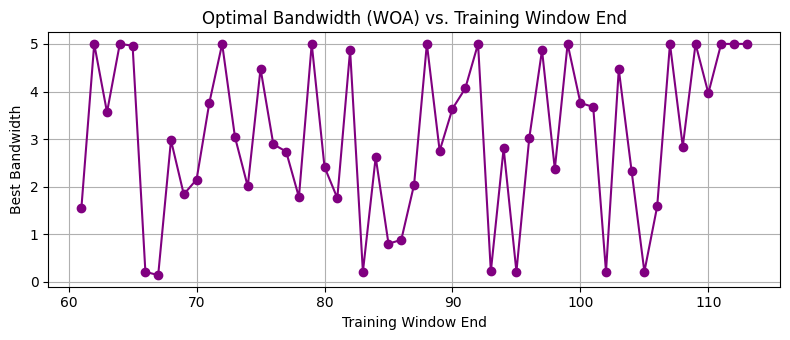

In [7]:
plt.figure(figsize=(8, 3.5))
plt.plot(window_results['WindowEnd'], window_results['BestBW'], marker='o', color='purple')
plt.title('Optimal Bandwidth (WOA) vs. Training Window End')
plt.xlabel('Training Window End')
plt.ylabel('Best Bandwidth')
plt.grid(True)
plt.tight_layout()
plt.show()


**Train Final Model & Forecast Test Data**


Best Overall Bandwidth (WOA): 3.0446


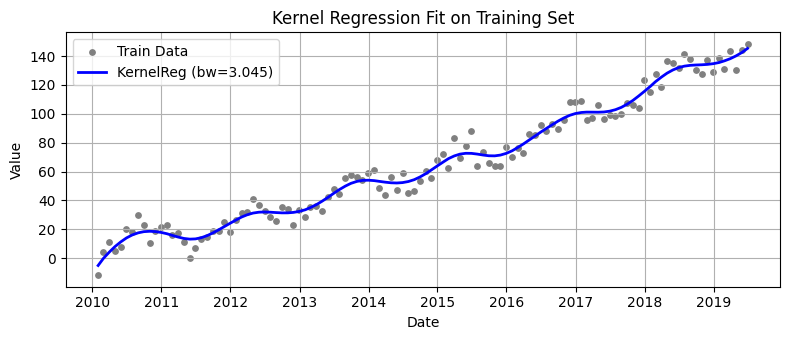

In [8]:
best_bw_overall = window_results.loc[window_results['MSE'].idxmin(), 'BestBW']
print(f"\nBest Overall Bandwidth (WOA): {best_bw_overall:.4f}")

X_full_train = np.arange(len(train)).reshape(-1, 1)
y_full_train = train['Value'].values
model_final = KernelReg(endog=y_full_train, exog=X_full_train, var_type='c', bw=[best_bw_overall])
y_fit_train, _ = model_final.fit(X_full_train)

plt.figure(figsize=(8, 3.5))
plt.scatter(train.index, train['Value'], color='gray', label='Train Data', s=15)
plt.plot(train.index, y_fit_train, color='blue', label=f'KernelReg (bw={best_bw_overall:.3f})', linewidth=2)
plt.title('Kernel Regression Fit on Training Set')
plt.xlabel('Date')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


**Forecast & Evaluate on Test Data**

Test RMSE: 5.461
Test MAPE: 3.170%


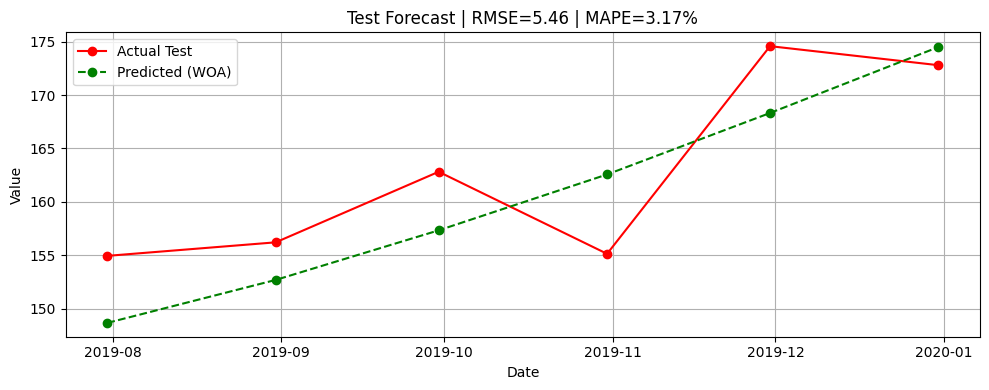

In [9]:
X_test = np.arange(len(train), len(train) + len(test)).reshape(-1, 1)
y_test_pred, _ = model_final.fit(X_test)
y_test_actual = test['Value'].values

test_rmse = np.sqrt(mean_squared_error(y_test_actual, y_test_pred))
test_mape = mean_absolute_percentage_error(y_test_actual, y_test_pred) * 100

print(f"Test RMSE: {test_rmse:.3f}")
print(f"Test MAPE: {test_mape:.3f}%")

plt.figure(figsize=(10, 4))
plt.plot(test.index, y_test_actual, 'ro-', label='Actual Test')
plt.plot(test.index, y_test_pred, 'go--', label='Predicted (WOA)')
plt.title(f'Test Forecast | RMSE={test_rmse:.2f} | MAPE={test_mape:.2f}%')
plt.xlabel('Date')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
